Задание 1. Первичный анализ данных

Загрузите датасет и исследуйте его структуру. Подсказка: используйте read_csv(), head(), info(), describe(), isnull(). Определите количество станков, типы оборудования, режимы работы и наличие пропущенных значений.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from pathlib import Path

filename = "telemetriya_stankov_360.csv"
if not Path(filename).exists():
    try:
        from google.colab import files
        print("Выберите файл:", filename)
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            f"Поместите {filename} в папку с notebook и запустите ячейку снова."
        )

if not Path(filename).exists():
    raise FileNotFoundError(f"Файл {filename} не найден после загрузки.")

df = pd.read_csv(filename)
display(df.head())
print()
print("Информация по датасету:")
print(df.info())
print()
print("Количество станков:", df.shape[0])
print("Пропуски по столбцам:\n", df.isna().sum().to_string())
print("Типы оборудования:", df["machine_type"].value_counts().to_dict())
print("Режимы:", df["mode"].value_counts().to_dict())


,machine_id,machine_type,mode,current_A,temperature_C,vibration_before_mm_s,vibration_after_mm_s
0,CNC-174,turning,high_load,13.45,67.16,5.67,5.31
1,CNC-065,milling,work,13.65,47.91,5.11,4.16
2,CNC-050,turning,idle,3.46,28.37,2.57,1.60
3,CNC-099,milling,work,10.21,51.01,4.47,3.88
4,CNC-072,turning,work,12.28,68.99,3.56,3.00



Информация по датасету:
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   machine_id             360 non-null    str    
 1   machine_type           360 non-null    str    
 2   mode                   360 non-null    str    
 3   current_A              360 non-null    float64
 4   temperature_C          360 non-null    float64
 5   vibration_before_mm_s  360 non-null    float64
 6   vibration_after_mm_s   360 non-null    float64
dtypes: float64(4), str(3)
memory usage: 19.8 KB
None

Количество станков: 360
Пропуски по столбцам:
 machine_id               0
machine_type             0
mode                     0
current_A                0
temperature_C            0
vibration_before_mm_s    0
vibration_after_mm_s     0
Типы оборудования: {'turning': 180, 'milling': 180}
Режимы: {'high_load': 120, 'work': 120, 'idle': 120}


Задание 2. Основные статистические характеристики 

Для температуры (temperature_C), тока (current_A) и вибрации (vibration_before_mm_s) рассчитайте среднее, медиану, моду, дисперсию, стандартное отклонение, минимум, максимум и квартили. Подсказка: используйте mean(), median(), mode(), var(), std() и quantile(). Сравните полученные характеристики и объясните, что они говорят о работе оборудования.

In [6]:
stats_cols = ["temperature_C", "current_A", "vibration_before_mm_s"]

stats = pd.DataFrame({
    "mean": df[stats_cols].mean(),
    "median": df[stats_cols].median(),
    "mode": df[stats_cols].mode().iloc[0],
    "var": df[stats_cols].var(),
    "std": df[stats_cols].std(),
    "min": df[stats_cols].min(),
    "max": df[stats_cols].max(),
    "q1": df[stats_cols].quantile(0.25),
    "q3": df[stats_cols].quantile(0.75),
})
display(stats)

,mean,median,mode,var,std,min,max,q1,q3
temperature_C,48.993083,48.425,26.62,242.830543,15.583021,24.73,84.91,32.590,63.2200
current_A,10.965417,11.355,5.25,33.802862,5.814023,1.90,23.09,4.600,15.8700
vibration_before_mm_s,4.701000,4.755,5.19,3.791673,1.947222,0.78,10.12,3.025,6.2125


Задание 3. Математическое ожидание 

Оцените математическое ожидание температуры отдельно для фрезерных и токарных станков. Подсказка: используйте выборочное среднее как оценку математического ожидания. Сравните значения и сделайте вывод о типичной температуре двух видов оборудования.

In [7]:
mean_temp_by_type = df.groupby("machine_type")["temperature_C"].mean()
print("Оценка математического ожидания температуры по типам станков:")
print(mean_temp_by_type.to_string())

diff = mean_temp_by_type.max() - mean_temp_by_type.min()
print(f"\nРазница между типами: {diff:.2f} °C")

Оценка математического ожидания температуры по типам станков:
machine_type
milling    49.069944
turning    48.916222

Разница между типами: 0.15 °C


Задание 4. Визуализация распределений 

Постройте гистограммы температуры и тока, а также boxplot вибрации для разных режимов работы. Подсказка: используйте hist() и boxplot(). Определите наличие асимметрии, разброса значений и возможных выбросов.

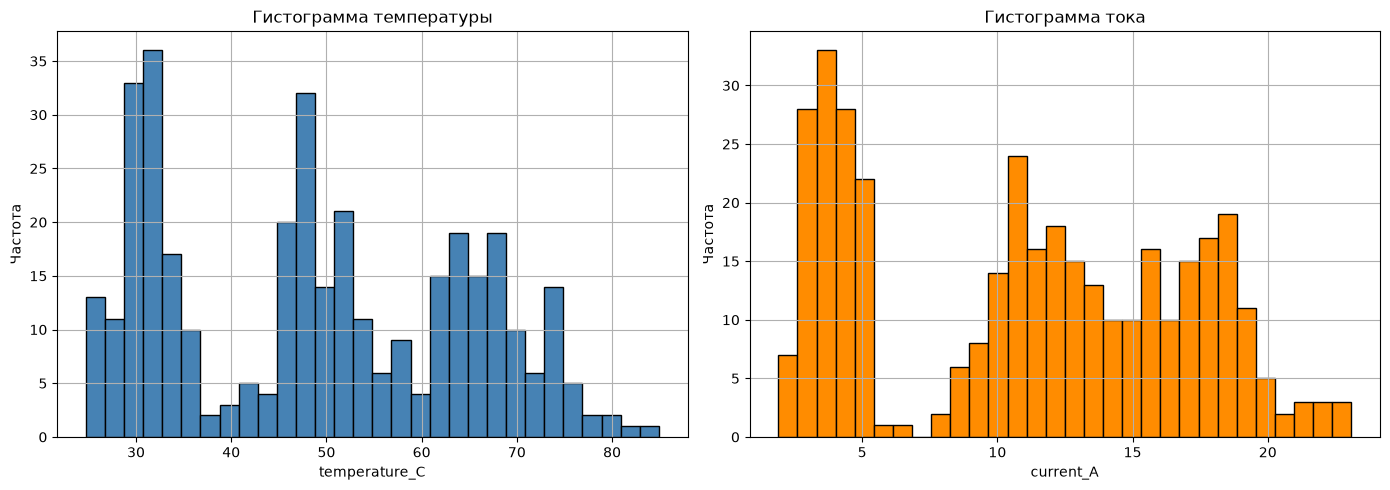

<Figure size 1200x600 with 0 Axes>

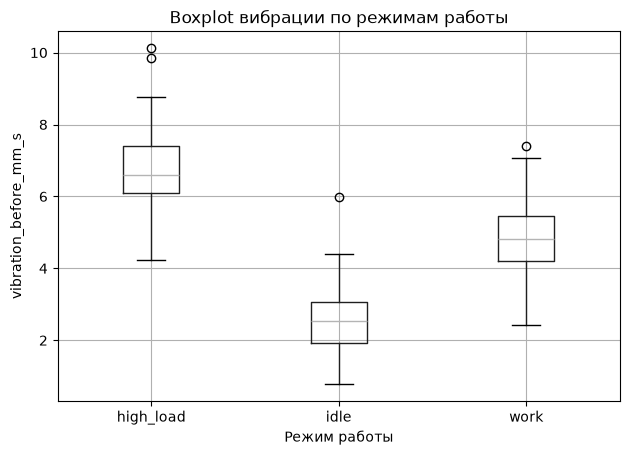

Асимметрия (skew):
temperature_C    0.145711
current_A        0.017604


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["temperature_C"].hist(ax=axes[0], bins=30, color="steelblue", edgecolor="black")
axes[0].set_title("Гистограмма температуры")
axes[0].set_xlabel("temperature_C")
axes[0].set_ylabel("Частота")

df["current_A"].hist(ax=axes[1], bins=30, color="darkorange", edgecolor="black")
axes[1].set_title("Гистограмма тока")
axes[1].set_xlabel("current_A")
axes[1].set_ylabel("Частота")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
df.boxplot(column="vibration_before_mm_s", by="mode", grid=True)
plt.title("Boxplot вибрации по режимам работы")
plt.suptitle("")
plt.xlabel("Режим работы")
plt.ylabel("vibration_before_mm_s")
plt.tight_layout()
plt.show()

print("Асимметрия (skew):")
print(df[["temperature_C", "current_A"]].skew().to_string())

Задание 5. Проверка статистической гипотезы 

Проверьте гипотезу о том, что средняя температура станков в режиме ожидания (idle) равна 30 °C. Подсказка: сформулируйте H₀ и H₁, выберите уровень значимости α = 0,05 и используйте scipy.stats.ttest_1samp(). Рассчитайте p-value и объясните, отвергается ли нулевая гипотеза.

In [9]:
from scipy import stats

idle_temp = df.loc[df["mode"] == "idle", "temperature_C"]

t_stat, p_value = stats.ttest_1samp(idle_temp, popmean=30)

print("H0: средняя температура в режиме idle = 30 °C")
print("H1: средняя температура в режиме idle ≠ 30 °C")
print(f"alpha = 0.05")
print(f"n = {len(idle_temp)}")
print(f"Выборочное среднее = {idle_temp.mean():.4f} °C")
print(f"t-статистика = {t_stat:.4f}")
print(f"p-value = {p_value:.6f}")

if p_value < 0.05:
    print("p-value < 0.05 → нулевая гипотеза отвергается: средняя температура значимо отличается от 30 °C.")
else:
    print("p-value >= 0.05 → нет оснований отвергнуть нулевую гипотезу: средняя температура значимо не отличается от 30 °C.")

H0: средняя температура в режиме idle = 30 °C
H1: средняя температура в режиме idle ≠ 30 °C
alpha = 0.05
n = 120
Выборочное среднее = 30.7940 °C
t-статистика = 3.2301
p-value = 0.001600
p-value < 0.05 → нулевая гипотеза отвергается: средняя температура значимо отличается от 30 °C.


Задание 6. Критерий Манна — Уитни 

Проверьте, различаются ли температуры фрезерных и токарных станков в режиме обычной работы (work). Подсказка: сформируйте две независимые группы, постройте boxplot и используйте scipy.stats.mannwhitneyu(). Сравните p-value с 0,05 и сформулируйте вывод.

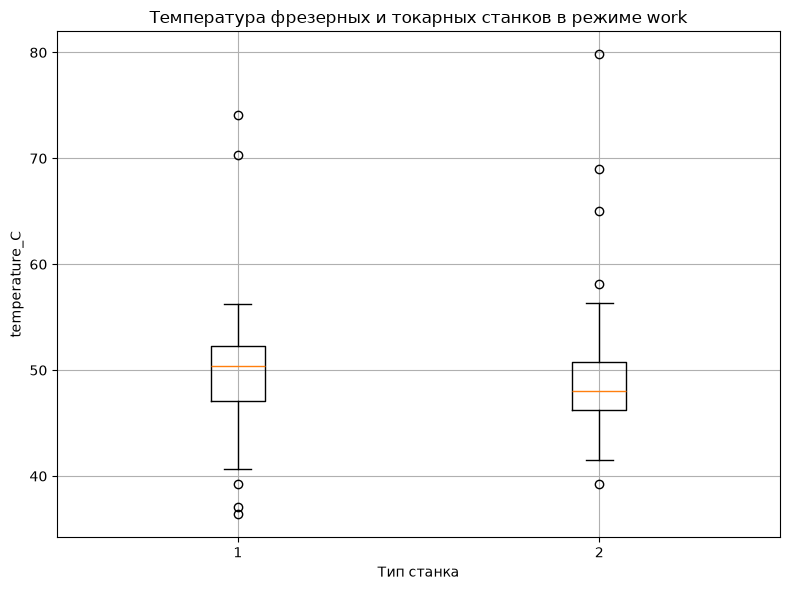

H0: распределения температур фрезерных и токарных станков в режиме work одинаковы
H1: распределения температур различаются
alpha = 0.05
n_milling = 60, n_turning = 60
Медиана milling = 50.4350 °C
Медиана turning = 48.0700 °C
U-статистика = 2149.0000
p-value = 0.067375
p-value >= 0.05 → нет оснований отвергнуть нулевую гипотезу: значимых различий температур не обнаружено.


In [12]:
from scipy import stats

work_df = df[df["mode"] == "work"]

temp_milling = work_df.loc[work_df["machine_type"] == "milling", "temperature_C"]
temp_turning = work_df.loc[work_df["machine_type"] == "turning", "temperature_C"]

plt.figure(figsize=(8, 6))
plt.boxplot([temp_milling, temp_turning], label=["milling", "turning"])
plt.title("Температура фрезерных и токарных станков в режиме work")
plt.xlabel("Тип станка")
plt.ylabel("temperature_C")
plt.grid(True)
plt.tight_layout()
plt.show()

u_stat, p_value = stats.mannwhitneyu(temp_milling, temp_turning, alternative="two-sided")

print("H0: распределения температур фрезерных и токарных станков в режиме work одинаковы")
print("H1: распределения температур различаются")
print(f"alpha = 0.05")
print(f"n_milling = {len(temp_milling)}, n_turning = {len(temp_turning)}")
print(f"Медиана milling = {temp_milling.median():.4f} °C")
print(f"Медиана turning = {temp_turning.median():.4f} °C")
print(f"U-статистика = {u_stat:.4f}")
print(f"p-value = {p_value:.6f}")

if p_value < 0.05:
    print("p-value < 0.05 → нулевая гипотеза отвергается: температуры фрезерных и токарных станков в режиме work значимо различаются.")
else:
    print("p-value >= 0.05 → нет оснований отвергнуть нулевую гипотезу: значимых различий температур не обнаружено.")


Задание 7. Критерий Уилкоксона 

Определите, изменился ли уровень вибрации оборудования после технического обслуживания. Подсказка: сравните vibration_before_mm_s и vibration_after_mm_s с помощью scipy.stats.wilcoxon(). Учитывайте, что измерения связаны между собой, так как относятся к одним и тем же станкам.

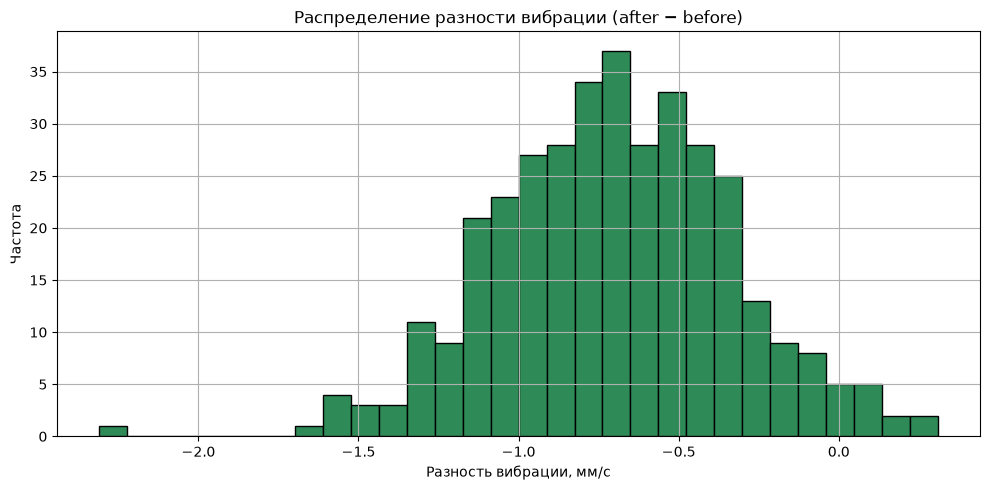

H0: медиана разности vibration_after − vibration_before = 0 (вибрация не изменилась)
H1: медиана разности ≠ 0 (вибрация изменилась после ТО)
alpha = 0.05
n = 360
Медиана before = 4.7550 мм/с
Медиана after  = 4.1750 мм/с
Медиана разности = -0.7000 мм/с
W-статистика = 185.0000
p-value = 0.000000
p-value < 0.05 → нулевая гипотеза отвергается: уровень вибрации значимо изменился после технического обслуживания.


In [13]:
from scipy import stats

vib_before = df["vibration_before_mm_s"]
vib_after = df["vibration_after_mm_s"]
diff = vib_after - vib_before

plt.figure(figsize=(10, 5))
plt.hist(diff, bins=30, color="seagreen", edgecolor="black")
plt.title("Распределение разности вибрации (after − before)")
plt.xlabel("Разность вибрации, мм/с")
plt.ylabel("Частота")
plt.grid(True)
plt.tight_layout()
plt.show()

w_stat, p_value = stats.wilcoxon(vib_before, vib_after)

print("H0: медиана разности vibration_after − vibration_before = 0 (вибрация не изменилась)")
print("H1: медиана разности ≠ 0 (вибрация изменилась после ТО)")
print(f"alpha = 0.05")
print(f"n = {len(diff)}")
print(f"Медиана before = {vib_before.median():.4f} мм/с")
print(f"Медиана after  = {vib_after.median():.4f} мм/с")
print(f"Медиана разности = {diff.median():.4f} мм/с")
print(f"W-статистика = {w_stat:.4f}")
print(f"p-value = {p_value:.6f}")

if p_value < 0.05:
    print("p-value < 0.05 → нулевая гипотеза отвергается: уровень вибрации значимо изменился после технического обслуживания.")
else:
    print("p-value >= 0.05 → нет оснований отвергнуть нулевую гипотезу: значимых изменений вибрации после ТО не обнаружено.")
    

Задание 8. Корреляция Спирмена 

Исследуйте наличие монотонной зависимости между потребляемым током и температурой станков. Подсказка: используйте scipy.stats.spearmanr(). Определите коэффициент корреляции ρ и p-value, объясните направление и силу зависимости.

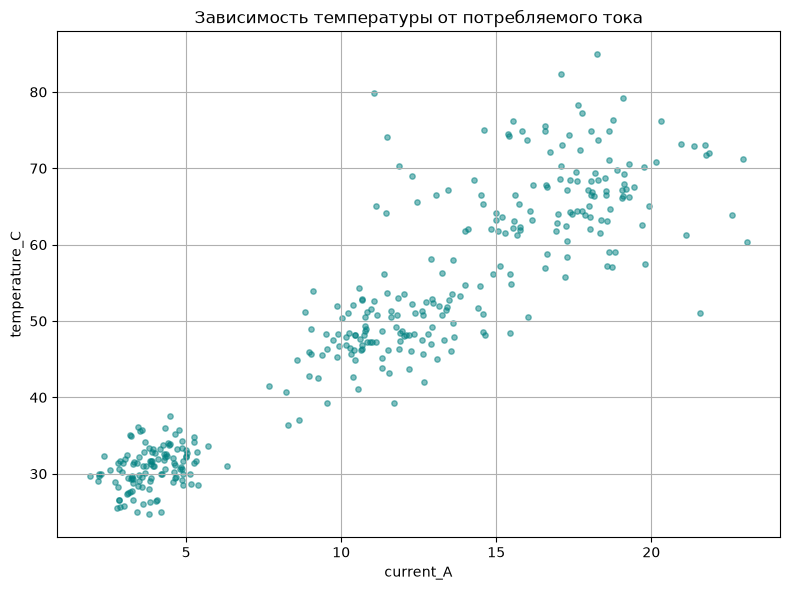

H0: монотонной зависимости между током и температурой нет (ρ = 0)
H1: монотонная зависимость присутствует (ρ ≠ 0)
alpha = 0.05
n = 360
Коэффициент Спирмена ρ = 0.9051
p-value = 5.051565e-135
Направление связи: положительная (рост тока сопровождается ростом температуры)
Сила связи: сильная (|ρ| = 0.9051)
p-value < 0.05 → нулевая гипотеза отвергается: монотонная зависимость статистически значима.


In [14]:
from scipy import stats

current = df["current_A"]
temperature = df["temperature_C"]

rho, p_value = stats.spearmanr(current, temperature)

plt.figure(figsize=(8, 6))
plt.scatter(current, temperature, alpha=0.5, s=15, color="teal")
plt.title("Зависимость температуры от потребляемого тока")
plt.xlabel("current_A")
plt.ylabel("temperature_C")
plt.grid(True)
plt.tight_layout()
plt.show()

print("H0: монотонной зависимости между током и температурой нет (ρ = 0)")
print("H1: монотонная зависимость присутствует (ρ ≠ 0)")
print(f"alpha = 0.05")
print(f"n = {len(df)}")
print(f"Коэффициент Спирмена ρ = {rho:.4f}")
print(f"p-value = {p_value:.6e}")

abs_rho = abs(rho)
if abs_rho < 0.2:
    strength = "очень слабая"
elif abs_rho < 0.4:
    strength = "слабая"
elif abs_rho < 0.6:
    strength = "умеренная"
elif abs_rho < 0.8:
    strength = "заметная"
else:
    strength = "сильная"

direction = "положительная (рост тока сопровождается ростом температуры)" if rho > 0 else "отрицательная (рост тока сопровождается снижением температуры)"

print(f"Направление связи: {direction}")
print(f"Сила связи: {strength} (|ρ| = {abs_rho:.4f})")

if p_value < 0.05:
    print("p-value < 0.05 → нулевая гипотеза отвергается: монотонная зависимость статистически значима.")
else:
    print("p-value >= 0.05 → нет оснований отвергнуть нулевую гипотезу: значимой монотонной зависимости не обнаружено.")


Задание 9. Критерий Краскела — Уоллиса 

Проверьте, различаются ли распределения температуры оборудования в трех режимах: idle, work и high_load. Подсказка: используйте scipy.stats.kruskal(). Постройте диаграмму сравнения режимов и определите, существуют ли статистически значимые различия. Укажите, позволяет ли этот критерий определить конкретные пары различающихся режимов.

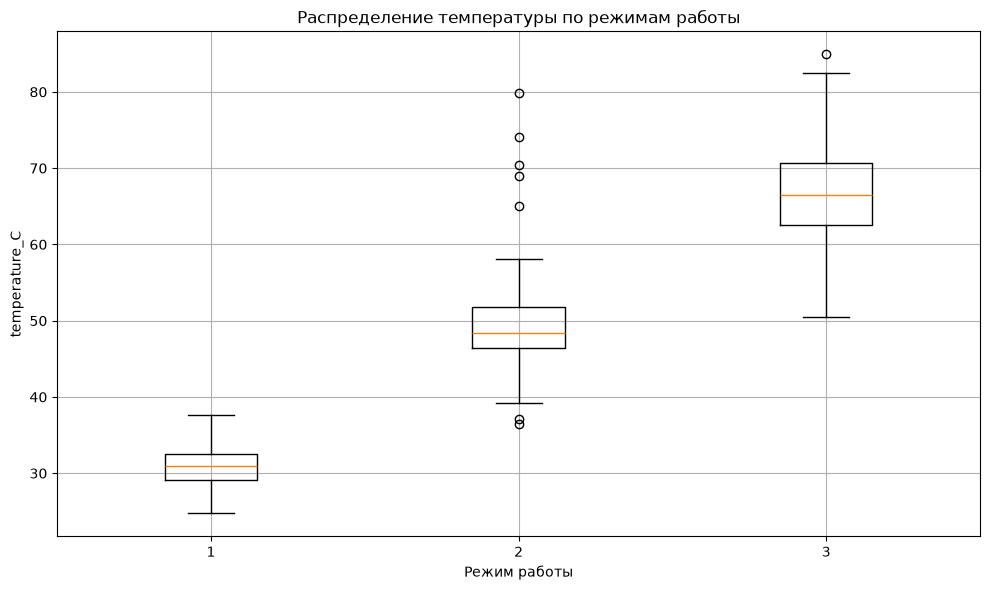

H0: распределения температуры в режимах idle, work и high_load одинаковы
H1: хотя бы одно распределение отличается от остальных
alpha = 0.05
n_idle = 120, медиана = 30.9750 °C, среднее = 30.7940 °C
n_work = 120, медиана = 48.4250 °C, среднее = 49.5269 °C
n_high_load = 120, медиана = 66.4650 °C, среднее = 66.6583 °C
H-статистика = 307.7041
p-value = 1.523735e-67
p-value < 0.05 → нулевая гипотеза отвергается: распределения температуры по режимам значимо различаются.


In [16]:
from scipy import stats

groups = {mode: df.loc[df["mode"] == mode, "temperature_C"] for mode in ["idle", "work", "high_load"]}

plt.figure(figsize=(10, 6))
plt.boxplot([groups["idle"], groups["work"], groups["high_load"]], label=["idle", "work", "high_load"])
plt.title("Распределение температуры по режимам работы")
plt.xlabel("Режим работы")
plt.ylabel("temperature_C")
plt.grid(True)
plt.tight_layout()
plt.show()

h_stat, p_value = stats.kruskal(groups["idle"], groups["work"], groups["high_load"])

print("H0: распределения температуры в режимах idle, work и high_load одинаковы")
print("H1: хотя бы одно распределение отличается от остальных")
print(f"alpha = 0.05")
for mode, vals in groups.items():
    print(f"n_{mode} = {len(vals)}, медиана = {vals.median():.4f} °C, среднее = {vals.mean():.4f} °C")
print(f"H-статистика = {h_stat:.4f}")
print(f"p-value = {p_value:.6e}")

if p_value < 0.05:
    print("p-value < 0.05 → нулевая гипотеза отвергается: распределения температуры по режимам значимо различаются.")
else:
    print("p-value >= 0.05 → нет оснований отвергнуть нулевую гипотезу: значимых различий между режимами не обнаружено.")

Задание 10. Общие выводы 

Сформулируйте общий вывод о работе оборудования на основании проведенного анализа. Подсказка: ответьте на вопросы: какие режимы характеризуются большей температурой и вибрацией, изменились ли показатели после обслуживания, какие взаимосвязи обнаружены и какие статистические методы оказались полезны. Требования к результату 
Необходимо сделать командную презентацию с указанием команды (до 5 человек) и их ролей. Скрины добавить из Jupyter Notebook.

Ответ